# All-channel EEG motif recovery: awake vs. isoflurane

This notebook runs and interprets the all-channel pilot analysis for mouse **688277**. It asks whether missing EEG motifs can be recovered by keeping continuous band-envelope values and/or applying common-average referencing (CAR).

For every valid EEG channel, we compare four conditions:

| Voltage reference | Motif representation |
|---|---|
| Original | Binary signs |
| Original | Continuous band values |
| CAR | Binary signs |
| CAR | Continuous band values |

> **Scope warning:** the available files are short 120-second windows from mouse 688277. This is a pipeline pilot. Final biological claims still require the full recordings, both target mice, more null permutations, and held-out validation.

## 0. Setup

The expensive analysis is controlled by `RUN_ANALYSIS`. Leave it `False` when you only want to reopen saved results. `N_NULL=3` is useful for debugging, but it is too small for final statistical claims.

In [1]:
%matplotlib inline

from pathlib import Path
import sys

REPO = Path.cwd().resolve()
while REPO != REPO.parent and not (REPO / 'code/python/src').exists():
    REPO = REPO.parent
if not (REPO / 'code/python/src').exists():
    raise RuntimeError('Could not find the dc-allen repository root.')
sys.path.insert(0, str(REPO / 'code/python'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.eeg_motif_diagnostics import load_window, run_diagnostics
from src.eeg_motif_batch import detection_summary, outcome_summary, run_batch
from src.gmm_motifs import bic_sweep, fit_gmm_motifs, seed_stability
from src.smooth_env import DEFAULT_FREQ_BANDS, smooth_env

INPUTS = {
    'awake': REPO / 'data/sample_nwb/688277-20230921-v001_awake.h5',
    'isoflurane': REPO / 'data/sample_nwb/688277-20230921-v001_iso_anesthetized.h5',
}
OUT_ROOT = REPO / 'data/out/eeg_all_channels_688277'
N_NULL = 3
SEED = 0
GMM_K = 5
GMM_K_MAX = 8
GMM_SEEDS = 5
RUN_TRANSITION = True
RUN_ANALYSIS = False

for state, path in INPUTS.items():
    print(f'{state:12s}: exists={path.exists()}  {path}')

awake       : exists=True  /Users/justinyu/Desktop/code/dc-allen/data/sample_nwb/688277-20230921-v001_awake.h5
isoflurane  : exists=True  /Users/justinyu/Desktop/code/dc-allen/data/sample_nwb/688277-20230921-v001_iso_anesthetized.h5


## 1. Run every valid channel

For each state, `run_diagnostics` performs CAR, measures channel quality, creates band envelopes, and runs both binary and continuous hierarchical motif detection before saving figures and `channel_summary.csv`.

Why is this slow? Each valid channel is filtered into six frequency bands twice—once using the original voltage and once after CAR. Motif detection is then repeated for both representations and every circular-shift null.

In [2]:
if RUN_ANALYSIS:
    for state, path in INPUTS.items():
        print(f'Running all valid channels: {state}...')
        table = run_diagnostics(
            path, OUT_ROOT / state, n_null=N_NULL, seed=SEED,
            gmm_k=GMM_K, gmm_k_max=GMM_K_MAX, gmm_seeds=GMM_SEEDS,
            transition=RUN_TRANSITION,
        )
        print(f'Finished {state}: {len(table) // 2} valid channels × 2 references')
else:
    print('Analysis not rerun. Set RUN_ANALYSIS=True only when you intentionally want to regenerate results.')

Analysis not rerun. Set RUN_ANALYSIS=True only when you intentionally want to regenerate results.


## 2. Load the saved channel tables

Each channel appears twice per state: once for the original voltage and once for CAR. A motif count of zero means the method did not find a pair that passed its filters under the current parameters. With only three nulls, any nonzero count remains exploratory.

In [3]:
tables = []
for state in INPUTS:
    csv_path = OUT_ROOT / state / 'channel_summary.csv'
    if csv_path.exists():
        frame = pd.read_csv(csv_path)
        frame['state'] = state
        tables.append(frame)
    else:
        print('Missing result:', csv_path)

if not tables:
    raise FileNotFoundError('No saved all-channel results yet. Run section 1 first.')
results = pd.concat(tables, ignore_index=True)
print('Rows:', len(results))
display(results.head())

Rows: 108


,channel,location,reference,binary_motif_pairs,continuous_motif_pairs,robust_sd_uv,peak_to_peak_uv,theta_fraction,line_noise_fraction,spectral_slope_2_40hz,x,y,z,state
0,0,VISl,original,1,1,60.118552,615.759216,0.231555,0.001423,-1.855209,377.0,58.0,82.0,awake
1,1,VISp,original,1,1,45.717094,553.881851,0.218063,0.001842,-1.824782,377.0,24.0,141.0,awake
2,2,RSPagl,original,1,1,36.066484,500.496384,0.192293,0.002462,-1.785806,377.0,20.0,188.0,awake
3,3,VISal,original,1,1,58.802616,3810.340088,0.230805,0.002297,-1.731419,333.0,47.0,79.0,awake
4,4,VISp,original,1,1,62.331025,622.018463,0.227081,0.001503,-1.857906,333.0,25.0,119.0,awake


## 3. How many channels recover a motif?

This is the main first-pass comparison. We count channels with at least one motif pair under each state, reference, and representation.

The strongest evidence that binarization is the problem would be many channels with `continuous > 0` but `binary = 0`. Evidence that shared reference activity is the problem would be more detections after CAR than before CAR.

,state,reference,method,channels_with_motif,total_channels,fraction
0,awake,car,binary,27,27,1.000000
1,awake,car,continuous,25,27,0.925926
2,awake,original,binary,25,27,0.925926
3,awake,original,continuous,25,27,0.925926
4,isoflurane,car,binary,0,27,0.000000
5,isoflurane,car,continuous,0,27,0.000000
6,isoflurane,original,binary,1,27,0.037037
7,isoflurane,original,continuous,0,27,0.000000


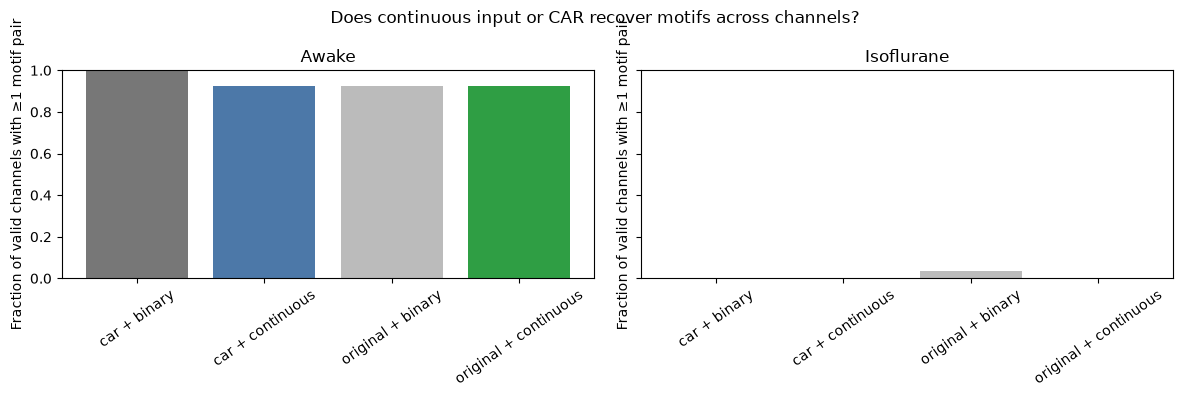

In [4]:
count_rows = []
for (state, reference), group in results.groupby(['state', 'reference']):
    for method in ['binary', 'continuous']:
        field = f'{method}_motif_pairs'
        count_rows.append({
            'state': state,
            'reference': reference,
            'method': method,
            'channels_with_motif': int((group[field] > 0).sum()),
            'total_channels': len(group),
            'fraction': float((group[field] > 0).mean()),
        })
detection_counts = pd.DataFrame(count_rows)
display(detection_counts)

fig, axes = plt.subplots(1, len(detection_counts.state.unique()), figsize=(12, 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, state in zip(axes, detection_counts.state.unique()):
    plot = detection_counts[detection_counts.state == state].copy()
    plot['condition'] = plot.reference + ' + ' + plot.method
    ax.bar(plot.condition, plot.fraction, color=['#777777', '#4c78a8', '#bbbbbb', '#2f9e44'])
    ax.set(title=state.title(), ylabel='Fraction of valid channels with ≥1 motif pair', ylim=(0, 1))
    ax.tick_params(axis='x', rotation=35)
fig.suptitle('Does continuous input or CAR recover motifs across channels?')
plt.tight_layout()
plt.show()

## 4. Channel-by-channel recovery map

A total count can hide whether the same channels succeed under different methods. This heatmap shows motif-pair counts for every channel. Vertical patterns indicate consistently strong or consistently problematic channels; changes between columns reveal method-specific rescue.

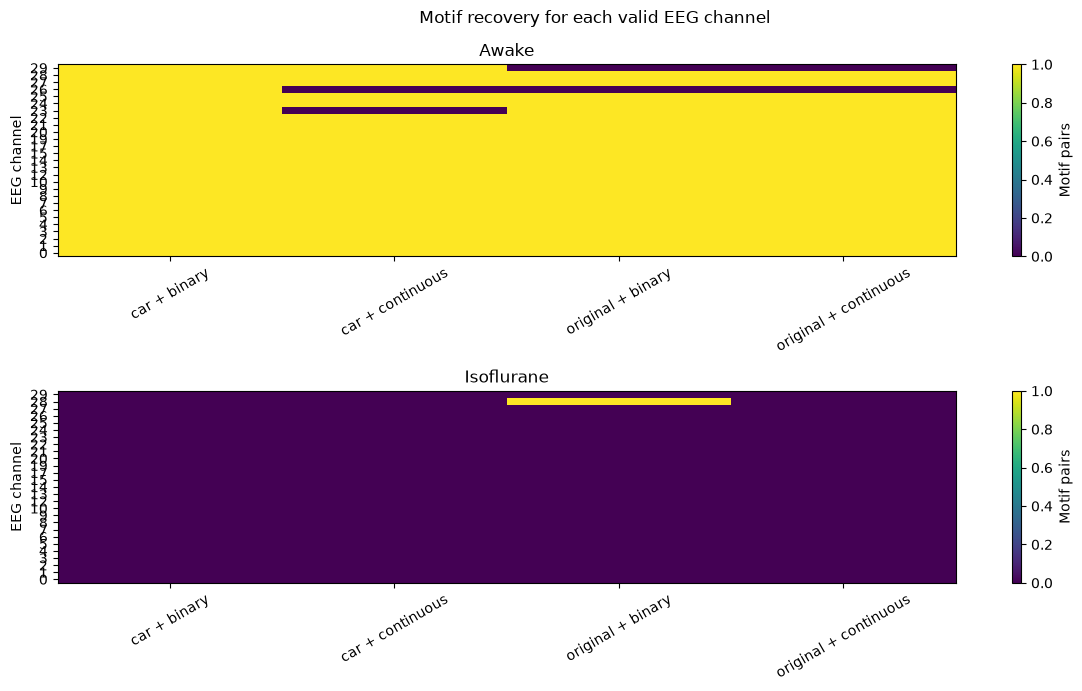

In [5]:
long_rows = []
for _, row in results.iterrows():
    for method in ['binary', 'continuous']:
        long_rows.append({
            'state': row.state, 'channel': row.channel, 'location': row.location,
            'condition': f'{row.reference} + {method}',
            'motif_pairs': row[f'{method}_motif_pairs'],
        })
long_results = pd.DataFrame(long_rows)

states = list(long_results.state.unique())
fig, axes = plt.subplots(len(states), 1, figsize=(12, 3.5 * len(states)), squeeze=False)
for ax, state in zip(axes[:, 0], states):
    matrix = long_results[long_results.state == state].pivot(index='channel', columns='condition', values='motif_pairs')
    image = ax.imshow(matrix.to_numpy(), aspect='auto', cmap='viridis', origin='lower')
    ax.set(yticks=range(len(matrix.index)), yticklabels=matrix.index,
           xticks=range(len(matrix.columns)), xticklabels=matrix.columns,
           ylabel='EEG channel', title=state.title())
    ax.tick_params(axis='x', rotation=30)
    fig.colorbar(image, ax=ax, label='Motif pairs')
fig.suptitle('Motif recovery for each valid EEG channel')
plt.tight_layout()
plt.show()

## 5. Which exact channels are rescued?

We classify a channel as:

- **continuous rescue:** binary found nothing, continuous found a motif;
- **binary only:** binary found a motif but continuous did not;
- **both:** both methods found at least one motif;
- **neither:** neither method found one.

This is more informative than asking only which method has the larger total.

In [6]:
classification = results[['state', 'reference', 'channel', 'location', 'binary_motif_pairs', 'continuous_motif_pairs']].copy()
binary = classification.binary_motif_pairs > 0
continuous = classification.continuous_motif_pairs > 0
classification['outcome'] = np.select(
    [~binary & continuous, binary & ~continuous, binary & continuous],
    ['continuous rescue', 'binary only', 'both'],
    default='neither',
)
display(classification.sort_values(['state', 'reference', 'outcome', 'channel']))
display(classification.groupby(['state', 'reference', 'outcome']).size().rename('channels').reset_index())

,state,reference,channel,location,binary_motif_pairs,continuous_motif_pairs,outcome
47,awake,car,23,SSp-bfd,1,0,binary only
50,awake,car,26,VISal,1,0,binary only
27,awake,car,0,VISl,1,1,both
28,awake,car,1,VISp,1,1,both
29,awake,car,2,RSPagl,1,1,both
...,...,...,...,...,...,...,...
75,isoflurane,original,24,RSPagl,0,0,neither
76,isoflurane,original,25,VISp,0,0,neither
77,isoflurane,original,26,VISal,0,0,neither
78,isoflurane,original,27,RSPagl,0,0,neither


,state,reference,outcome,channels
0,awake,car,binary only,2
1,awake,car,both,25
2,awake,original,both,25
3,awake,original,neither,2
4,isoflurane,car,neither,27
5,isoflurane,original,binary only,1
6,isoflurane,original,neither,26


## 6. Are successful channels less noisy or spectrally different?

A method can fail because of the algorithm or because the input channel is poor. We compare robust voltage variation, theta fraction, 60 Hz contamination, and spectral slope between channels with and without continuous motifs.

These are descriptive plots. With only one mouse and spatially correlated channels, ordinary channel-level p-values would overstate the evidence.

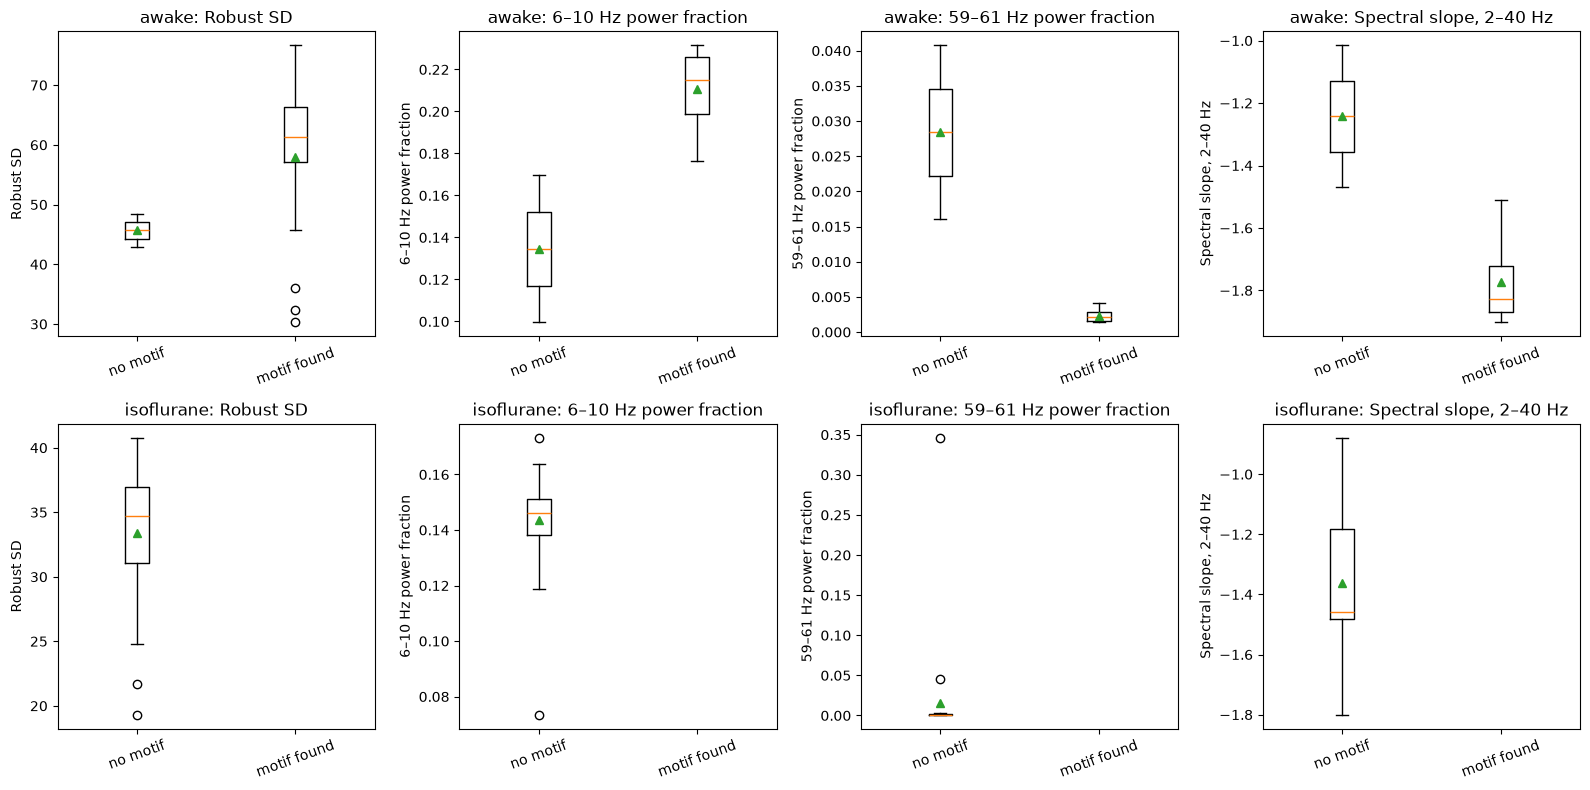

robust_sd_uv  theta_fraction  \
state      reference continuous_detected                                 
awake      car       False                     35.2922          0.1092   
                     True                      24.8859          0.1535   
           original  False                     45.6987          0.1347   
                     True                      61.2857          0.2151   
isoflurane car       False                     13.9363          0.1230   
           original  False                     34.6817          0.1460   

                                          line_noise_fraction  \
state      reference continuous_detected                        
awake      car       False                             0.0130   
                     True                              0.0047   
           original  False                             0.0284   
                     True                              0.0021   
isoflurane car       False                             0.0050   
           original  False                             0.0012   

                                          spectral_slope_2_40hz  
state      reference continuous_detected                         
awake      car       False                              -1.0860  
                     True                               -1.5848  
           original  False                              -1.2419  
                     True                               -1.8271  
isoflurane car       False                              -0.9323  
           original  False                              -1.4570

In [7]:
metrics_to_plot = [
    ('robust_sd_uv', 'Robust SD'),
    ('theta_fraction', '6–10 Hz power fraction'),
    ('line_noise_fraction', '59–61 Hz power fraction'),
    ('spectral_slope_2_40hz', 'Spectral slope, 2–40 Hz'),
]
fig, axes = plt.subplots(len(states), len(metrics_to_plot), figsize=(16, 4 * len(states)), squeeze=False)
for row_index, state in enumerate(states):
    subset = results[(results.state == state) & (results.reference == 'original')].copy()
    subset['continuous_detected'] = np.where(subset.continuous_motif_pairs > 0, 'motif found', 'no motif')
    for ax, (field, label) in zip(axes[row_index], metrics_to_plot):
        groups = [subset.loc[subset.continuous_detected == name, field].dropna() for name in ['no motif', 'motif found']]
        ax.boxplot(groups, tick_labels=['no motif', 'motif found'], showmeans=True)
        ax.set(title=f'{state}: {label}', ylabel=label)
        ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

metric_summary = (results.assign(continuous_detected=results.continuous_motif_pairs > 0)
                  .groupby(['state', 'reference', 'continuous_detected'])
                  [[field for field, _ in metrics_to_plot]].median().round(4))
display(metric_summary)

## 7. Does anatomical location matter?

EEG channels sample different brain regions. If neighboring or anatomically related channels succeed together, that supports a biological location effect. If isolated channels behave unlike every neighbor, channel quality becomes a stronger explanation.

Because some locations contain very few channels, always report both the count and denominator.

In [8]:
location_summary = (results.assign(
        binary_detected=results.binary_motif_pairs > 0,
        continuous_detected=results.continuous_motif_pairs > 0,
    ).groupby(['state', 'reference', 'location'])
     .agg(channels=('channel', 'nunique'),
          binary_fraction=('binary_detected', 'mean'),
          continuous_fraction=('continuous_detected', 'mean'))
     .reset_index())
display(location_summary.sort_values(['state', 'reference', 'continuous_fraction'], ascending=[True, True, False]))

,state,reference,location,channels,binary_fraction,continuous_fraction
0,awake,car,MOs,5,1.00,1.00
1,awake,car,RSPagl,6,1.00,1.00
3,awake,car,SSp-ll,2,1.00,1.00
4,awake,car,VISa,2,1.00,1.00
6,awake,car,VISl,2,1.00,1.00
7,awake,car,VISp,4,1.00,1.00
2,awake,car,SSp-bfd,4,1.00,0.75
5,awake,car,VISal,2,1.00,0.50
8,awake,original,MOs,5,1.00,1.00
9,awake,original,RSPagl,6,1.00,1.00


## 8. Does CAR rescue or remove motifs?

CAR subtracts activity shared across valid EEG channels. A positive change means CAR revealed a motif that was hidden before; a negative change means CAR removed a detected pattern. The latter could be shared artifact **or** genuine widespread neural activity, so it requires inspection of the raw/CAR plots.

,state,channel,location,method,change_after_car
23,awake,26,VISal,binary,1
26,awake,29,VISl,binary,1
47,awake,23,SSp-bfd,continuous,-1
53,awake,29,VISl,continuous,1
79,isoflurane,28,VISp,binary,-1


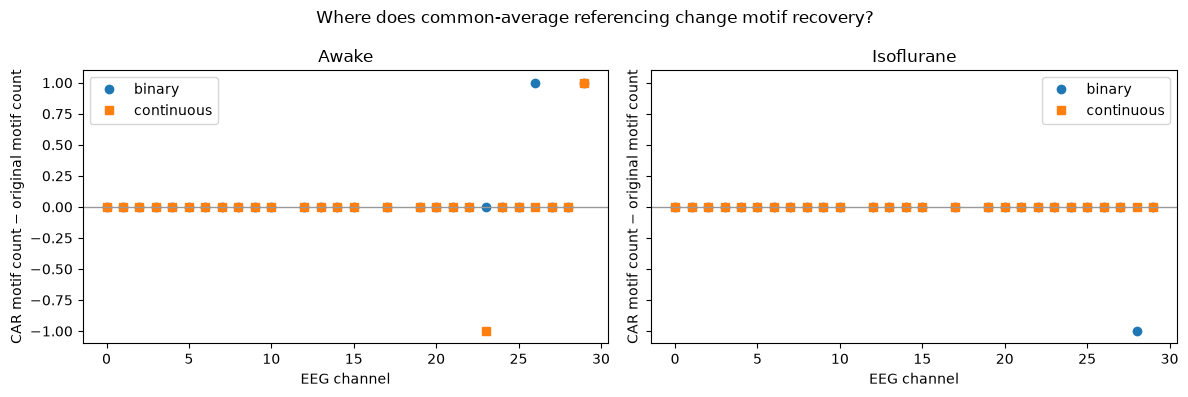

In [9]:
car_rows = []
for state in states:
    subset = results[results.state == state].set_index(['channel', 'location', 'reference'])
    for method in ['binary', 'continuous']:
        field = f'{method}_motif_pairs'
        wide = subset[field].unstack('reference')
        wide['change_after_car'] = wide.get('car', 0) - wide.get('original', 0)
        for (channel, location), row in wide.iterrows():
            car_rows.append({'state': state, 'channel': channel, 'location': location,
                             'method': method, 'change_after_car': row.change_after_car})
car_effect = pd.DataFrame(car_rows)
display(car_effect[car_effect.change_after_car != 0].sort_values(['state', 'method', 'change_after_car']))

fig, axes = plt.subplots(1, len(states), figsize=(12, 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, state in zip(axes, states):
    subset = car_effect[car_effect.state == state]
    for method, marker in [('binary', 'o'), ('continuous', 's')]:
        group = subset[subset.method == method]
        ax.plot(group.channel, group.change_after_car, marker=marker, ls='none', label=method)
    ax.axhline(0, color='0.6', lw=1)
    ax.set(title=state.title(), xlabel='EEG channel', ylabel='CAR motif count − original motif count')
    ax.legend()
fig.suptitle('Where does common-average referencing change motif recovery?')
plt.tight_layout()
plt.show()

## 9. Awake versus isoflurane on matched channels

This comparison asks whether a channel's motif recovery changes with brain state. Because each extracted window is z-scored separately and is only 120 seconds long, this is a preliminary state comparison—not a complete transition analysis.

In [10]:
if {'awake', 'isoflurane'}.issubset(set(results.state)):
    matched = results.pivot_table(
        index=['channel', 'location', 'reference'],
        columns='state',
        values=['binary_motif_pairs', 'continuous_motif_pairs'],
    )
    display(matched)
else:
    print('Both state result tables are required for this section.')

binary_motif_pairs             \
state                                   awake isoflurane   
channel location reference                                 
0       VISl     car                      1.0        0.0   
                 original                 1.0        0.0   
1       VISp     car                      1.0        0.0   
                 original                 1.0        0.0   
2       RSPagl   car                      1.0        0.0   
                 original                 1.0        0.0   
3       VISal    car                      1.0        0.0   
                 original                 1.0        0.0   
4       VISp     car                      1.0        0.0   
                 original                 1.0        0.0   
5       RSPagl   car                      1.0        0.0   
                 original                 1.0        0.0   
6       SSp-bfd  car                      1.0        0.0   
                 original                 1.0        0.0   
7       VISa     car                      1.0        0.0   
                 original                 1.0        0.0   
8       RSPagl   car                      1.0        0.0   
                 original                 1.0        0.0   
9       SSp-bfd  car                      1.0        0.0   
                 original                 1.0        0.0   
10      SSp-ll   car                      1.0        0.0   
                 original                 1.0        0.0   
12      MOs      car                      1.0        0.0   
                 original                 1.0        0.0   
13      MOs      car                      1.0        0.0   
                 original                 1.0        0.0   
14      MOs      car                      1.0        0.0   
                 original                 1.0        0.0   
15      MOs      car                      1.0        0.0   
                 original                 1.0        0.0   
17      MOs      car                      1.0        0.0   
                 original                 1.0        0.0   
19      SSp-ll   car                      1.0        0.0   
                 original                 1.0        0.0   
20      SSp-bfd  car                      1.0        0.0   
                 original                 1.0        0.0   
21      RSPagl   car                      1.0        0.0   
                 original                 1.0        0.0   
22      VISa     car                      1.0        0.0   
                 original                 1.0        0.0   
23      SSp-bfd  car                      1.0        0.0   
                 original                 1.0        0.0   
24      RSPagl   car                      1.0        0.0   
                 original                 1.0        0.0   
25      VISp     car                      1.0        0.0   
                 original                 1.0        0.0   
26      VISal    car                      1.0        0.0   
                 original                 0.0        0.0   
27      RSPagl   car                      1.0        0.0   
                 original                 1.0        0.0   
28      VISp     car                      1.0        0.0   
                 original                 1.0        1.0   
29      VISl     car                      1.0        0.0   
                 original                 0.0        0.0   

                           continuous_motif_pairs             
state                                       awake isoflurane  
channel location reference                                    
0       VISl     car                          1.0        0.0  
                 original                     1.0        0.0  
1       VISp     car                          1.0        0.0  
                 original                     1.0        0.0  
2       RSPagl   car                          1.0        0.0  
                 original                     1.0        0.0  
3       VISal    car                   

## 10. Optional GMM follow-up on representative channels

The hierarchical all-channel table is the cleanest binary-ablation experiment. GMM is a complementary model. Instead of calling every GMM cluster a motif, choose representative channels from the table and check BIC, five-seed stability, and cluster centers.

Set `RUN_GMM_FOLLOWUP=True` after reviewing the recovery map. The example automatically selects the awake original-reference channel with the largest continuous motif count.

In [11]:
RUN_GMM_FOLLOWUP = False
GMM_K = 5

if RUN_GMM_FOLLOWUP:
    candidates = results[(results.state == 'awake') & (results.reference == 'original')]
    selected = candidates.sort_values(['continuous_motif_pairs', 'robust_sd_uv'], ascending=[False, True]).iloc[0]
    channel = int(selected.channel)
    window = load_window(INPUTS['awake'])
    env = smooth_env(window['eeg'][:, channel], window['fs'], DEFAULT_FREQ_BANDS)
    clean = env[np.isfinite(env).all(axis=1)]
    env_1hz = clean[::max(1, int(round(window['fs'])))]
    ks, bics = bic_sweep(env_1hz, range(1, 13))
    gmm = fit_gmm_motifs(env_1hz, GMM_K, seed=0, n_init=5)
    stability, mean_ari = seed_stability(env_1hz, GMM_K, seeds=range(5))
    print(f'Channel {channel}, {selected.location}; K={GMM_K}; mean seed ARI={mean_ari:.3f}')
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(ks, bics, 'o-')
    axes[0].axvline(GMM_K, color='C3', ls=':')
    axes[0].set(xlabel='K', ylabel='BIC', title='K selection')
    labels = [f'{lo:g}–{hi:g} Hz' for lo, hi in DEFAULT_FREQ_BANDS]
    for index, center in enumerate(gmm.centers):
        axes[1].plot(labels, center, 'o-', label=f'cluster {index}')
    axes[1].axhline(0, color='0.7', lw=1)
    axes[1].set(ylabel='Mean envelope z-score', title='GMM cluster centers')
    axes[1].tick_params(axis='x', rotation=35)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print('GMM follow-up skipped until the hierarchical all-channel results are reviewed.')

GMM follow-up skipped until the hierarchical all-channel results are reviewed.


## 11. How to write the conclusion

Use the observed pattern—not the hoped-for result:

- If continuous rescues many channels: **binarization discarded useful EEG magnitude information.**
- If CAR rescues many channels: **shared reference activity or common noise masked channel-specific structure.**
- If success tracks low noise or certain regions: **signal quality or anatomy explains part of the EEG/LFP difference.**
- If GMM clusters are unstable: **the apparent continuous states are not yet reliable motifs.**
- If awake and iso differ: **state-specific analysis is necessary; combining them can hide patterns.**

Do not claim that EEG matches LFP yet. That requires simultaneous EEG–LFP correspondence, behavior/stimulation controls, full recordings, both target mice, and stronger null/held-out evaluation.

### Observed pilot result (mouse 688277, 120-second windows, 3 nulls)

- Awake original reference: binary and continuous each detected motifs in 25/27 channels. They succeeded on the same 25 channels; continuous input rescued no additional channel.
- Awake CAR: binary detected motifs in 27/27 channels, while continuous detected 25/27. CAR therefore rescued two binary detections but did not improve continuous detection.
- Isoflurane original reference: binary detected one motif on channel 28 (VISp); continuous detected none.
- Isoflurane CAR: neither representation detected a motif on any channel.

The pilot therefore does **not** support the simple claim that binarization alone explains missing EEG motifs. It does show a large awake-versus-isoflurane contrast and a small CAR effect during awake. Because almost every awake channel passes under the very weak three-null pilot, the next methodological question is whether these detections survive stronger null testing and longer, stimulation-controlled windows.